In [18]:
%load_ext autoreload
%autoreload 2
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import obspy as obs                   # obs.read, obs.read_inventory, obs.UTCDateTime
import obspy.geodetics as obsgeo      # obsgeo.gps2dist_azimuth
import seisbench.models as sbm
#local scripts import
import sys
sys.path.append("../scripts/py")

import HypoDD as hdd
import phase_pick as pp
import plots

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
stations_data = pd.read_csv("../data/input_data/station.dat", sep=r"\s+", header=None,
                       names=["sta", "lat", "lon", "elev"])

#2. loading catalog
cat = pp.load_catalog()

dist = pp.calculate_distance(cat, stations_data)
dist[["epi_km", "hypo_km"]].agg(["mean", "max"])


,epi_km,hypo_km
mean,3.647053,4.536753
max,8.643000,9.394000


In [ ]:
#creating ph2dt.inp

hdd.ph2dt_input(
    station_file="station.dat",   # in data/input_data (from create_station_dat.py)
    phase_file="phase.dat",       # in data/input_data (from create_phase_dat)
    minwght=0.0,    # min pick weight used (0 = all)
    maxdist=10.0,   # max distance (km) event pair – station
    maxsep=1.0,     # max separation (km) between the two events of a pair
    maxngh=10,      # max neighbours per event
    minlnk=4,       # min shared picks for a "strong" neighbour
    minobs=4,       # min shared picks for a pair to be saved
    maxobs=50,      # max shared picks saved per pair
)


Wrote /rcp/rcp42/home/esotelo/location_project/data/input_data/ph2dt.inp
* ph2dt.inp - input control file for program ph2dt
* written by scripts/py/HypoDD.py, ph2dt_input()
* Input station file:
station.dat
* Input phase file:
phase.dat
*MINWGHT: min. pick weight allowed [0]
*MAXDIST: max. distance in km between event pair and stations [200]
*MAXSEP: max. hypocentral separation in km [10]
*MAXNGH: max. number of neighbors per event [10]
*MINLNK: min. number of links required to define a neighbor [8]
*MINOBS: min. number of links per pair saved [8]
*MAXOBS: max. number of links per pair saved [20]
*MINWGHT MAXDIST MAXSEP MAXNGH MINLNK MINOBS MAXOBS
   0      10     1     10      4      4     50



PosixPath('/rcp/rcp42/home/esotelo/location_project/data/input_data/ph2dt.inp')

In [13]:
hdd.run_ph2dt()

starting ph2dt (v2.1b - 08/2012)...     Sun Oct  4 19:23:07 2026 

reading data ...
 > stations =           13
 > events total =         1741
 > events selected =         1741
 > phases =        18890
forming dtimes...
 > stations selected =           11
 > P-phase pairs total =       196175
 > S-phase pairs total =       147403
 > outliers =       152544  (          44 %)
 > phases at stations not in station list =            0
 > phases at distances larger than MAXDIST =            0
 > P-phase pairs selected =        41701  (          21 %)
 > S-phase pairs selected =        43949  (          29 %)
 > weakly linked events =           26  (           1 %)
 > linked event pairs =        11689
 > average links per pair =            7
 > average offset (km) betw. linked events =    4.08670157E-02
 > average offset (km) betw. strongly linked events =    4.08670157E-02
 > maximum offset (km) betw. strongly linked events =   0.764354110    

Done.  Sun Oct  4 19:23:10 2026 

Output files: 

True

In [14]:
import HypoDD as hdd

hdd.create_hypodd_input(
    # --- input files (in data/input_data) ---
    dtcc_file="",                # cross-correlation diff. times; "" = none (catalog-only run)
    dtct_file="dt.ct",           # catalog diff. times from ph2dt
    event_file="event.sel",      # starting locations from ph2dt
    station_file="station.dat",  # STA LAT LON ELEV (m above sea level)
    # --- output files ---
    loc_file="hypoDD.loc",       # starting locations as read by hypoDD
    reloc_file="hypoDD.reloc",   # relocated events (the result)
    sta_file="hypoDD.sta",       # residuals per station
    res_file="hypoDD.res",       # residuals per data point
    src_file="hypoDD.src",       # take-off angles
    # --- data selection ---
    idat=2,                      # 1 = cross-corr only, 2 = catalog only, 3 = both
    ipha=3,                      # 1 = P, 2 = S, 3 = P and S
    dist=15.0,                   # max distance (km) cluster centroid - station
    # --- clustering ---
    obscc=0,                     # min cross-corr links per pair to join a cluster
    obsct=4,                     # min catalog links per pair to join a cluster (= ph2dt minobs)
    minds=-999, maxds=-999,      # min/max distance (km) event pair - station (-999 = off)
    maxgap=-999,                 # max azimuthal gap (deg) (-999 = off)
    # --- solution control ---
    istart=2,                    # 1 = start from cluster centroid, 2 = from catalog locations
    isolv=2,                     # 1 = SVD (<= 215 events), 2 = LSQR (large problems)
    iaq=1,                       # 1 = remove air-quakes, 0 = keep (reset depth)
    # --- iterations: (NITER, WTCCP, WTCCS, WRCC, WDCC, WTCTP, WTCTS, WRCT, WDCT, DAMP) ---
    iterations=[
        (5, -999, -999, -999, -999, 1.0, 0.5, -999, -999, 100),   # all catalog data, no cutoffs
        (5, -999, -999, -999, -999, 1.0, 0.5,    6,  1.0, 100),   # outliers > 6 std, pairs <= 1 km
    ],
    # --- velocity model (depths in km below SEA LEVEL, same datum as phase.dat) ---
    imod=1,                      # 1 = layers with their own Vp/Vs
    top=[0.0, 0.01],             # layer tops (km below sea level)
    vp=[3.7, 5.8],               # Vp (km/s): station→sea level average | basement
    ratio=[1.83, 1.71],          # Vp/Vs of each layer
    # --- event selection ---
    cid=0,                       # cluster to relocate (0 = all)
    ids=None,                    # list of event IDs to relocate (None = all)
)


Wrote /rcp/rcp42/home/esotelo/location_project/data/input_data/hypoDD.inp
hypoDD_2
* hypoDD.inp - written by scripts/py/HypoDD.py, create_hypodd_input()
*--- INPUT FILES
* cross-correlation diff. times (blank: none):

* catalog diff. times:
dt.ct
* initial hypocenters:
event.sel
* stations:
station.dat
*--- OUTPUT FILES
* initial locations:
hypoDD.loc
* relocations:
hypoDD.reloc
* station residuals:
hypoDD.sta
* data residuals:
hypoDD.res
* take-off angles:
hypoDD.src
*--- DATA SELECTION
* IDAT  IPHA  DIST
  2  3  15
*--- EVENT CLUSTERING
* OBSCC  OBSCT  MINDS  MAXDS  MAXGAP
  0  4  -999  -999  -999
*--- SOLUTION CONTROL
* ISTART  ISOLV  IAQ  NSET
  2  2  1  2
*--- DATA WEIGHTING AND RE-WEIGHTING
* NITER WTCCP WTCCS WRCC WDCC WTCTP WTCTS WRCT WDCT DAMP
5 -999 -999 -999 -999 1 0.5 -999 -999 100
5 -999 -999 -999 -999 1 0.5 6 1 100
*--- FORWARD MODEL
* IMOD
1
* TOP (km below datum), end with -9
0 0.01 -9
* VELP (km/s), end with -9
3.7 5.8 -9
* RAT (Vp/Vs), end with -9
1.83 1.71 -9
*--- CL

PosixPath('/rcp/rcp42/home/esotelo/location_project/data/input_data/hypoDD.inp')

In [16]:
hdd.run_hypodd()    

Remove air quakes.
# events =  1741
# stations < maxdist =     13
# stations w/ neg. elevation (set to 0) =    0
# catalog P dtimes =   41701
# catalog S dtimes =   43949
# dtimes total =    85650
# events after dtime match =       1732
# stations =     11
Clustered events:  1732
Isolated events:     0
# clusters:    2
Cluster   1:  1730 events
Cluster   2:     2 events
RELOCATION OF CLUSTER: 1     Sun Oct  4 19:38:17 2026
# events =  1730
# stations < maxdist =     13
# stations w/ neg. elevation (set to 0) =    0
# catalog P dtimes =   41694
# catalog S dtimes =   43943
# dtimes total =    85637
# events after dtime match =       1730
# stations =     11
  IT   EV  CT    RMSCT   RMSST   DX   DY   DZ   DT   OS  AQ  CND
        %   %   ms     %    ms    m    m    m   ms    m 
 1    100 100   84 -28.1     0  198  152  216   28    0  66   56
 2     96  94   81  -3.1     0  183  138  181   25    0   4   54
 3     96  94   81  -0.5     0  182  137  177   25    0   2   54
 4  1  96  94   81

True

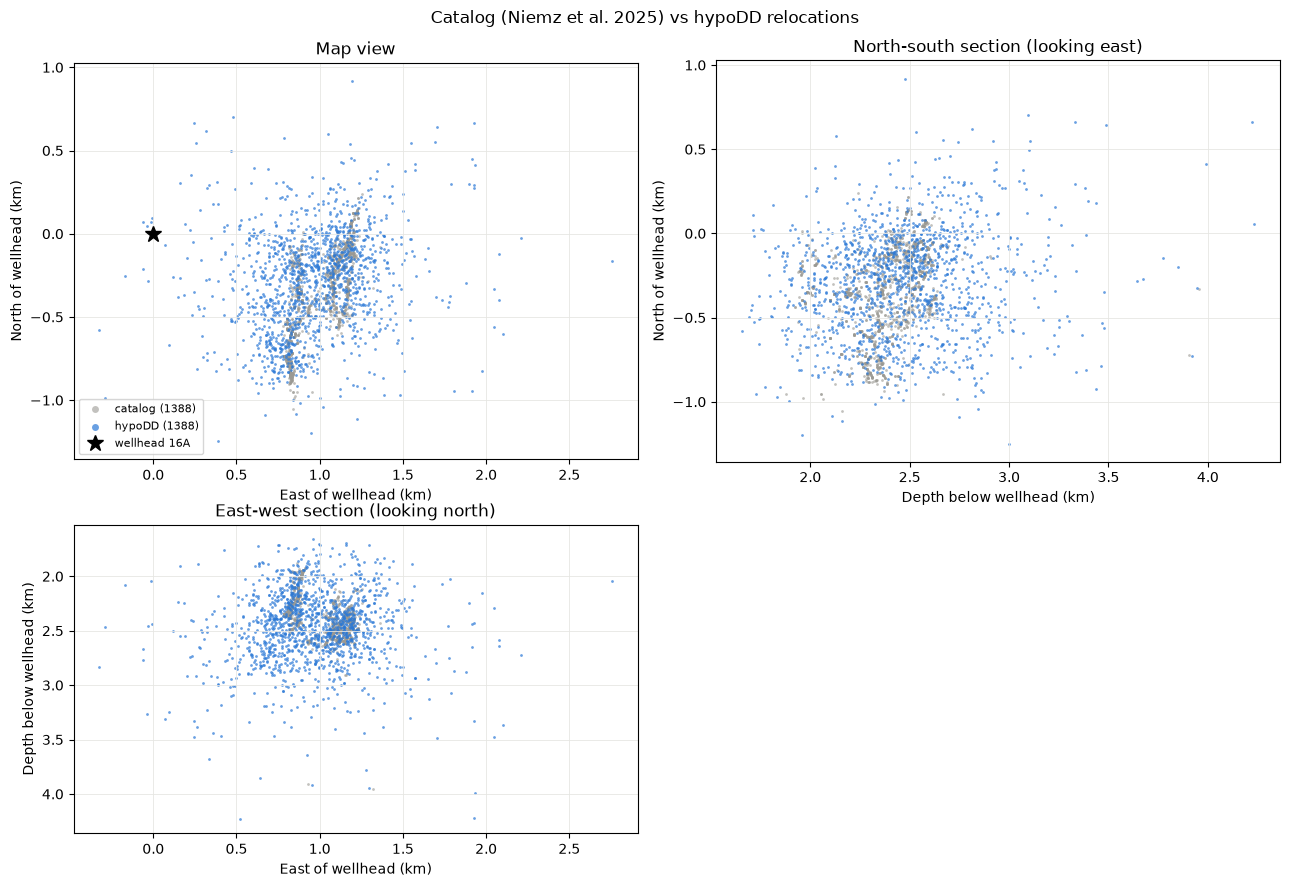

In [21]:
import HypoDD as hdd, plots
plt.close('all')
reloc = hdd.read_reloc()                     # hypoDD.reloc → table
plots.plot_relocation(cat, reloc)            # catalog vs hypoDD
#plots.plot_relocation(cat, reloc, size=6, figsize=(11, 8), title="run 1: DAMP 100")   # options
